# Examining the Relationship between Kudzu and the Kudzu Bug (Megacopta cribraria)

### Importing Libraries

In [30]:
%pip install mapclassify


[notice] A new release of pip is available: 23.1.2 -> 26.2.2
[notice] To update, run: pip3.11 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [31]:
import time
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib
import matplotlib.pyplot as plt
import mapclassify
from matplotlib.patches import Polygon, Patch, Rectangle
from matplotlib.lines import Line2D
from shapely.geometry import Polygon

## 1. Data Organization

In [32]:
PLANT = "Pueraria montana"
BUG = "Megacopta cribraria"
species = [PLANT, BUG]
year = "2021,2025"

api = "https://api.gbif.org/v1"
records = []

for name in species:
    response = requests.get(f"{api}/species/match",
                            params={"name": name, "strict": "true"}, timeout = 60)
    response.raise_for_status()
    match = response.json()
    if match.get("matchType") != "EXACT" or match.get("rank" != "SPECIES"):
        raise ValueError(f"Check the species name: {name}")
    taxonKey = match.get("acceptedUsageKey", match["usageKey"])

parameters = {
    "taxonKey": taxonKey,
    "country": "US",
    "year": year,
    "basisOfRecord": "HUMAN_OBSERVATION",
    "occurrenceStatus": "PRESENT",
    "hasCoordinate": "true",
    "hasGeospatialIssue": "false",
    "limit": 300,
    "offset": 0,
}

species_records = []
while True:
    response = requests.get(f"{api}/occurrence/search", params = parameters, timeout = 60)
    response.raise_for_status()
    page = response.json()
    if page["count"] > 9000:
        raise ValueError(f"{name} has too many records for this example.")
    for record in page["results"]:
        record["queried_species"] = name
    species_records.extend(page["results"])
    if page.get("endOfRecords") or not page["results"]:
        break
    parameters["offset"] += len(page["results"])
    time.sleep(0.2)

    records.extend(species_records)
    print(f"{name}: {len(species_records):,} records")

kudzu = pd.DataFrame(records)[["queried_species", "decimalLatitude", "decimalLongitude"]]

Megacopta cribraria: 300 records
Megacopta cribraria: 600 records
Megacopta cribraria: 900 records
Megacopta cribraria: 1,200 records
Megacopta cribraria: 1,500 records
Megacopta cribraria: 1,800 records
Megacopta cribraria: 2,100 records
Megacopta cribraria: 2,400 records
Megacopta cribraria: 2,700 records
Megacopta cribraria: 3,000 records
Megacopta cribraria: 3,300 records
Megacopta cribraria: 3,600 records


## 2. Regional Data

In [33]:
url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/"
states = gpd.read_file(url_0 + "cb_2024_us_state_500k.zip")

region_states = [
    # Deep South
    "FL", "GA", "AL", "MS", "LA", "AR", "SC",
    # Upper South 
    "NC", "TN", "KY", "VA", "WV",
    # Mid-Atlantic 
    "MD", "DC", "DE", "PA", "NJ",
]
region = states.loc[states["STUSPS"].isin(region_states)].to_crs(epsg=5070)

points = gpd.GeoDataFrame(
    kudzu.copy(),
    geometry=gpd.points_from_xy(kudzu["decimalLongitude"], kudzu["decimalLatitude"]),
    crs="EPSG:4326",
).to_crs(epsg=5070)

points_by_state = gpd.sjoin(
    points, region[["NAME", "geometry"]], how="inner", predicate="within"
).drop(columns="index_right")

counts = (
    points_by_state.groupby(["NAME", "queried_species"]).size()
    .unstack(fill_value=0)
    .reindex(columns=species, fill_value=0))

# colors: teal-green = kudzu, brown = kudzu bug
colors = {PLANT: "#01665e", BUG: "#8c510a"}
labels = {PLANT: "Kudzu (Pueraria montana)", BUG: "Kudzu bug (Megacopta cribraria)"}

## 3. Proportional Symbol Map

/var/folders/vp/bp9_y2ps4kgb176q8tsn453h0000gn/T/ipykernel_2926/3575015043.py:68: UserWarning: Numba not installed. Using slow pure python version.
  pieMap(ax, region, counts)


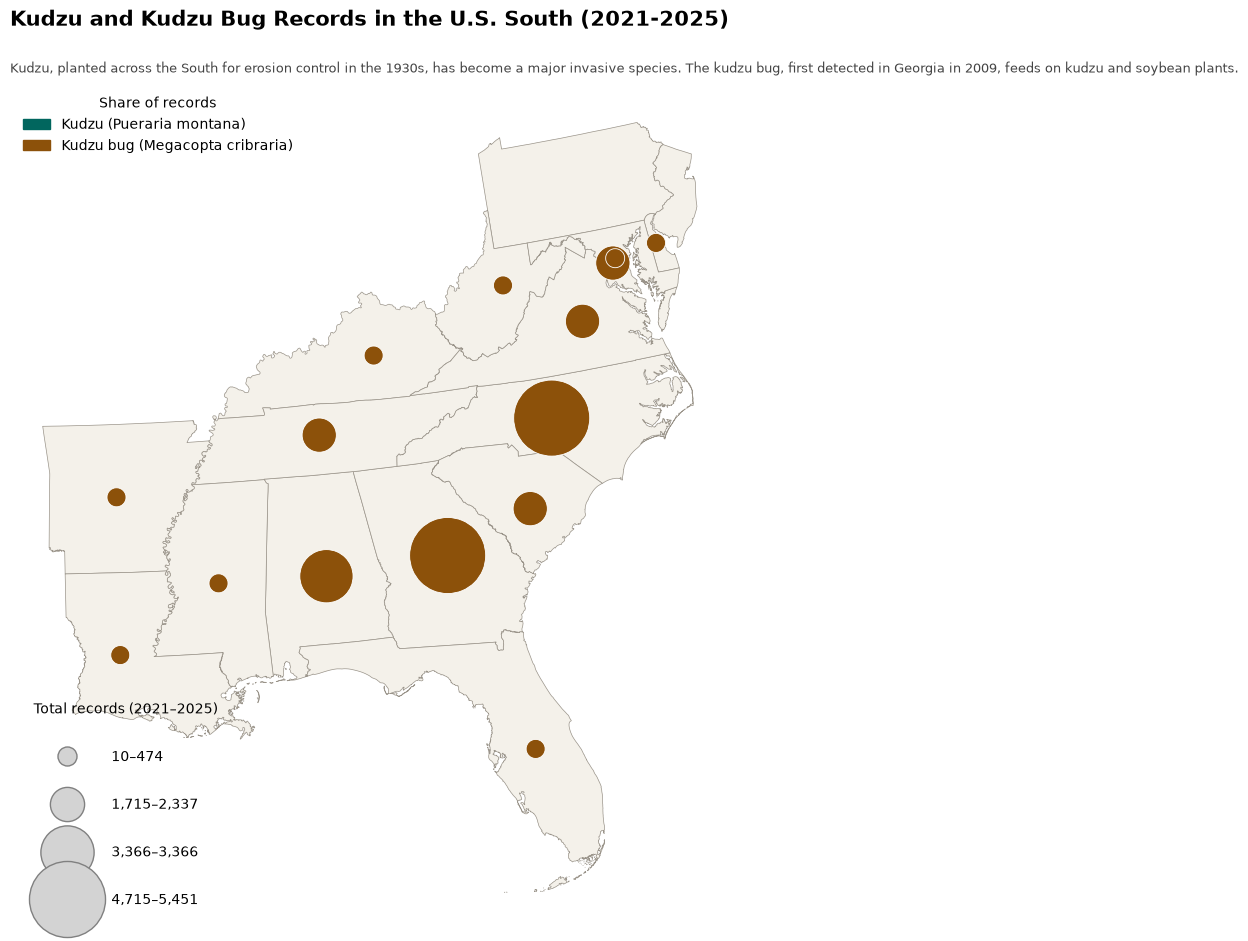

In [29]:
def pieMap(ax, region, counts):
    state_map = region.merge(counts, left_on="NAME", right_index=True, how="left")
    state_map[species] = state_map[species].fillna(0)
    state_map["total"] = state_map[species].sum(axis=1)
    positive = state_map.loc[state_map["total"] > 0].copy()

    classification = mapclassify.FisherJenks(positive["total"], k=4)
    positive["size_class"] = classification.yb

    state_map.plot(ax=ax, facecolor="#f4f1ea", edgecolor="#9a948a", linewidth=0.5)
    xlim, ylim = ax.get_xlim(), ax.get_ylim()

    radii = [25000, 45000, 70000, 100000] # meters for map

    # big pies drawn first so small ones may sit on top.
    for _, state in positive.sort_values("total", ascending=False).iterrows():

        parts = getattr(state.geometry, "geoms", [state.geometry])
        center = max(parts, key=lambda p: p.area).representative_point()
        # Drop zero slices so single-species states don't get a stray white line
        slices = [(state[n], colors[n]) for n in [PLANT, BUG] if state[n] > 0]
        ax.pie(
            [v for v, c in slices],
            colors=[c for v, c in slices],
            center=(center.x, center.y),
            radius=radii[int(state["size_class"])],
            startangle=90,
            counterclock=False,
            wedgeprops={"edgecolor": "white", "linewidth": 0.6},
        )
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_aspect("equal")

    species_legend = ax.legend(
        handles=[Patch(color=colors[PLANT], label=labels[PLANT]),
                 Patch(color=colors[BUG], label=labels[BUG])],
        loc="upper left", title="Share of records", frameon=False, fontsize=10,
    )
    ax.add_artist(species_legend)

    # Size legend to convert map radii to marker diameters in points
    ax.figure.canvas.draw()
    points_per_meter = ax.get_window_extent().width / (xlim[1] - xlim[0]) * 72 / ax.figure.dpi
    handles = []
    for class_id, radius in enumerate(radii):
        values = positive.loc[positive["size_class"] == class_id, "total"]
        handles.append(Line2D(
            [], [], linestyle="none", marker="o",
            markersize=2 * radius * points_per_meter,
            markerfacecolor="lightgray", markeredgecolor="gray",
            label=f"{values.min():,.0f}–{values.max():,.0f}",
    ))
    ax.legend(
        handles=handles, title="Total records (2021–2025)", loc="lower left",
        labelspacing=2.4, borderpad=1.2, handletextpad=2.2, frameon=False, fontsize=10)

    ax.set_title("Kudzu and Kudzu Bug Records in the U.S. South (2021-2025)",
                 fontsize=15, fontweight="bold", loc="left", pad=42
                )
    ax.text(0, 1.01, "Kudzu, planted across the South for erosion control in the 1930s, has become a major invasive species. The kudzu bug, first detected in Georgia in 2009, feeds on kudzu and soybean plants.",
            fontsize=9, transform=ax.transAxes, color="#444", va="bottom"
            )
    ax.set_axis_off()
    return ax

fig, ax = plt.subplots(figsize=(10, 11))
pieMap(ax, region, counts)
fig.savefig("kudzu_proportional_symbols.png", dpi=300, bbox_inches="tight")
plt.show()